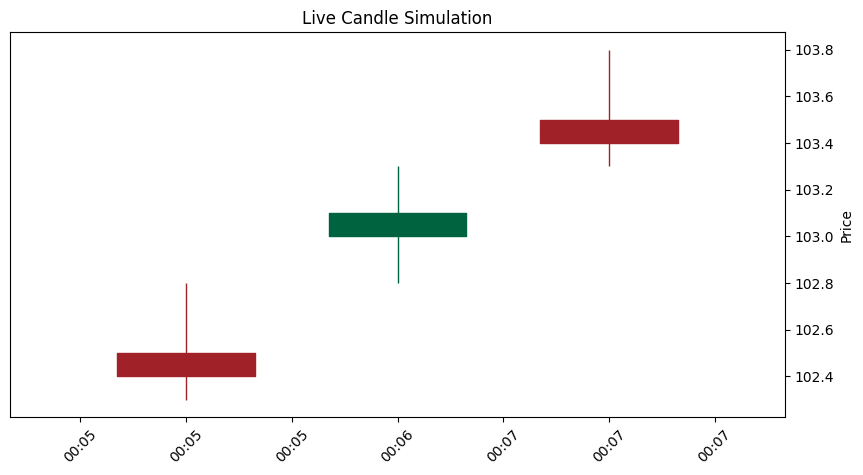

In [ ]:
import pandas as pd
import mplfinance as mpf
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
import time

# --- Example candle data (replace this with your real dataframe) ---
data = {
    'Date': pd.date_range("2023-01-01", periods=20, freq="1min"),
    'Open':  [100 + i*0.5 for i in range(20)],
    'High':  [100 + i*0.5 + 0.3 for i in range(20)],
    'Low':   [100 + i*0.5 - 0.2 for i in range(20)],
    'Close': [100 + i*0.5 + (0.1 if i % 2 == 0 else -0.1) for i in range(20)],
    'Volume':[1000 + i*10 for i in range(20)]
}
df = pd.DataFrame(data).set_index("Date")

# --- Parameters ---
update_interval = 1  # seconds per candle

# --- Matplotlib setup ---
fig, ax = plt.subplots(figsize=(10,5))
ax.set_title("Live Candle Simulation")

# keep track of how many candles have been shown
candle_count = [0]  

def update(frame):
    ax.clear()
    ax.set_title("Live Candle Simulation")

    # take first N candles
    n = candle_count[0] + 1
    df_partial = df.iloc[:n]

    # plot them
    mpf.plot(df_partial, type='candle', ax=ax, volume=False, style='charles')
    
    candle_count[0] = n % len(df)  # loop when reaching end

# ani = FuncAnimation(fig, update, interval=update_interval*1000)
from IPython.display import HTML

ani = FuncAnimation(fig, update,
                    frames=len(df),
                    interval=update_interval*1000,
                    repeat=True)

HTML(ani.to_jshtml())   # or ani.to_html5_video()


In [11]:
7.699999999999374/10000*100

0.07699999999999374

In [4]:
-0.0001*10000

-1.0

In [18]:
(0.9995)**9000

0.011096501781668664

In [8]:
59*20

1180

In [5]:
50*118

5900

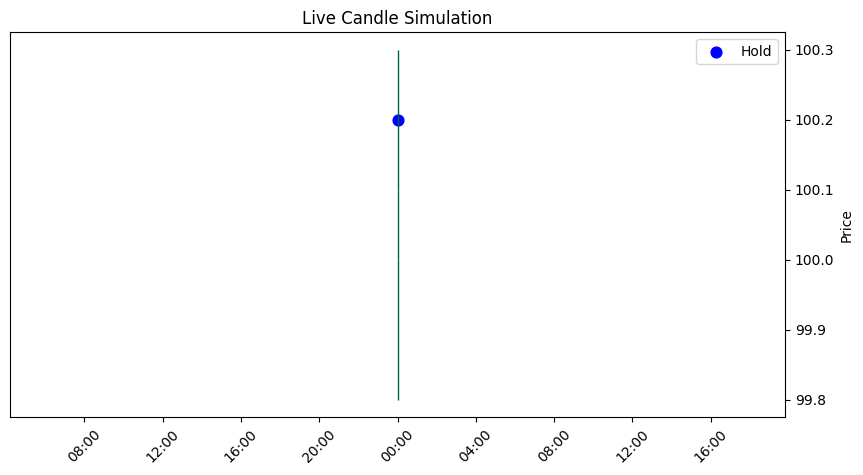

In [12]:
import pandas as pd
import mplfinance as mpf
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import numpy as np

# --- Example candle data ---
data = {
    'Date': pd.date_range("2023-01-01", periods=20, freq="1min"),
    'Open':  [100 + i*0.5 for i in range(20)],
    'High':  [100 + i*0.5 + 0.3 for i in range(20)],
    'Low':   [100 + i*0.5 - 0.2 for i in range(20)],
    'Close': [100 + i*0.5 + (0.1 if i % 2 == 0 else -0.1) for i in range(20)],
    'Volume':[1000 + i*10 for i in range(20)]
}
df = pd.DataFrame(data).set_index("Date")

# --- Example agent actions (0: noop, 1: buy, 2: sell, 3: hold) ---
actions = np.random.choice([0,1,2,3], size=len(df))

# --- Parameters ---
update_interval = 1  # seconds per candle

# --- Matplotlib setup ---
fig, ax = plt.subplots(figsize=(10,5))
ax.set_title("Live Candle Simulation")

def update(n):
    ax.clear()
    ax.set_title("Live Candle Simulation")

    # take first N candles (ensure n>=1)
    df_partial = df.iloc[:n]
    act_partial = actions[:n]

    # plot candlesticks
    mpf.plot(df_partial, type='candle', ax=ax, volume=False, style='charles', show_nontrading=True)

    # overlay agent actions on CLOSE price
    for date, close, high, low, act in zip(df_partial.index, 
                                           df_partial['Close'], 
                                           df_partial['High'], 
                                           df_partial['Low'], 
                                           act_partial):
        if act == 1:   # Buy → show above high
            ax.scatter(date, high * 1.002, marker="^", color="green", s=80, label="Buy" if n==1 else "")
        elif act == 2: # Sell → show below low
            ax.scatter(date, low * 0.998, marker="v", color="red", s=80, label="Sell" if n==1 else "")
        elif act == 3: # Hold → show just above close
            ax.scatter(date, close * 1.001, marker="o", color="blue", s=60, label="Hold" if n==1 else "")
        # 0 = noop → nothing

    if n == 1:  # only show legend once
        ax.legend()

ani = FuncAnimation(fig, update,
                    frames=range(1, len(df)+1),  # <-- start from 1
                    interval=update_interval*1000,
                    repeat=True)

HTML(ani.to_jshtml())


In [11]:
df

,Open,High,Low,Close,Volume
Date,,,,,
2023-01-01 00:00:00,100.0,100.3,99.8,100.1,1000
2023-01-01 00:01:00,100.5,100.8,100.3,100.4,1010
2023-01-01 00:02:00,101.0,101.3,100.8,101.1,1020
2023-01-01 00:03:00,101.5,101.8,101.3,101.4,1030
2023-01-01 00:04:00,102.0,102.3,101.8,102.1,1040
2023-01-01 00:05:00,102.5,102.8,102.3,102.4,1050
2023-01-01 00:06:00,103.0,103.3,102.8,103.1,1060
2023-01-01 00:07:00,103.5,103.8,103.3,103.4,1070
2023-01-01 00:08:00,104.0,104.3,103.8,104.1,1080
